# Chunk 54 — Independent replay fine-tuning per target resolution (50% target / 50% 25×25)

**Why:** the letter describes the fine-tuning as **independent** for each target resolution, starting from the same pretrained θ₀, with **every minibatch half target and half replayed 25×25 data**. Chunk 52 ran a sequential chain instead (12 → 15 → 35 → 45, replaying all grids, about 20% target per epoch). This chunk runs exactly the procedure the letter describes, on the same Chunk 51 datasets, so the method section and the numbers match.

**Design (pre-registered):**

| run | starts from | every minibatch (64) | selection |
|---|---|---|---|
| `ind_ft12` | `best_model.pt` (θ₀), widened to 6 inputs (zero column, exact) | 32 from the 12×12 train set + 32 from the 25×25 train set | 12×12 val MSE |
| `ind_ft15` | θ₀ | 32 from 15×15 + 32 from 25×25 | 15×15 val MSE |
| `ind_ft35` | θ₀ | 32 from 35×35 + 32 from 25×25 | 35×35 val MSE |
| `ind_ft45` | θ₀ | 32 from 45×45 + 32 from 25×25 | 45×45 val MSE |

- **The runs are independent:** none starts from another. Each produces its own set of weights, with the same 587,129-parameter architecture.
- **Every epoch:** all 4,000 target training antennas plus a fresh random draw of 4,000 from the 79,866 25×25 training antennas, arranged so that **each minibatch is exactly 32 target + 32 replay**. The loss is the batch MSE, which equals the letter's (J(Dₜ) + J(D₂₅)) / 2 because the halves are equal.
- **Recipe (unchanged from Chunks 42–52):**
  - **Optimiser:** Adam, lr 1e-4, weight decay 1e-4, gradient clipping 1.0.
  - **Schedule:** ReduceLROnPlateau (factor 0.5, patience 5); early stopping with patience 10; at most 60 epochs.
  - **Seeds:** torch 1000+s; sampling 5400 + 10·N + s.
- **Data:** the Chunk 51 splits for 12/15/35/45; the unchanged `indices.json` split for 25×25. Normalisation statistics fixed (25×25).
- **Restores `processed_35x35_extra.zip` if it was deleted,** rebuilding it from the raw files exactly as Chunk 45 did and verifying it against the Chunk 45 and Chunk 51 manifests (section 4b).

**Test (one touch):**
- **Every run** on all five test sets: its target grid (the headline) plus 25×25 for retention; the other grids for information only.
- **`best_model` zero-shot,** as the reference. On 25×25 it must reproduce MSE 1.3175 and MAE 0.3742.

**Paired comparisons** (same test antennas):
- each run vs the **Gupta CNN** (Chunk 53, seed 0), read from `ch53_per_sample.parquet`
- each run vs the **Chunk 52 chain** (`bal_ft45_s0`), read from `ch52_per_sample.parquet`

**Pre-registered statements:**

| | question |
|---|---|
| S1 | On each target grid, does the independent GATv2 beat zero-shot θ₀ (paired MSE and MAE)? |
| S2 | On each target grid, does it beat the Gupta CNN? |
| S3 | How much 25×25 accuracy does each independent run lose (vs θ₀)? |
| S4 | Independent vs the Chunk 52 chain, on each target grid: better, worse or no significant difference? |

**Writes:**
- `ch54_*` artifacts: runs, curves, per-sample with predicted curves, metrics, paired comparisons, report
- `ch54_table_gatv2_vs_cnn.{png,pdf}` (MAE and RMSE, as in the letter's Table I)
- `checkpoints/ch54_*.pt`
- `data/processed/processed_35x35_extra.zip`, **only if it was missing** (restored, not changed)

## 1. Installs

In [2]:
!pip -q install torch_geometric pyarrow tabulate

## 2. Repository and Drive

In [3]:
import os, sys, subprocess
REPO_ROOT = '/content/antenna_gnn'
if os.path.isdir(f'{REPO_ROOT}/.git'):
    subprocess.run(['git', '-C', REPO_ROOT, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/asparagusD/antenna_gnn.git', REPO_ROOT], check=True)
sys.path.insert(0, f'{REPO_ROOT}/src')
from google.colab import drive
drive.mount('/content/drive')
DATA_ROOT = '/content/drive/MyDrive/antenna_gnn'
ART, CKPT, SPLITS, LOCAL = f'{DATA_ROOT}/artifacts', f'{DATA_ROOT}/checkpoints', f'{DATA_ROOT}/splits', '/content/local_graphs'
os.makedirs(LOCAL, exist_ok=True)
print(REPO_ROOT, DATA_ROOT)

Mounted at /content/drive
/content/antenna_gnn /content/drive/MyDrive/antenna_gnn


## 3. Setup
- **Determinism:** deterministic cuDNN, TF32 off.
- **Provenance:** hashes every input file and captures the mtimes of earlier files, so the guards can prove nothing earlier was changed.
- **Statistics:** loads the canonical 25×25 normalisation statistics read-only.

In [4]:
# ── Setup: scope, provenance, determinism ──
import json, glob, hashlib, zipfile, shutil, time, copy
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GeoLoader
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
from model import AntennaGNN
from feed_component import AppendFeedComponentFeature

TAU, F = -10.0, np.linspace(1, 4, 201)
NEW = (12, 15, 35, 45); GRIDS = (12, 15, 25, 35, 45)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); assert DEVICE.type == 'cuda', 'GPU required'
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
def sha(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()
READ_SHA = {}
def READ(p):
    assert os.path.exists(p), f'missing {p}'
    READ_SHA.setdefault(p, sha(p)); return p
def OUT(n):
    assert n.startswith('ch54_'), n; return f'{ART}/{n}'
def COUT(n):
    assert n.startswith('ch54_') and n.endswith('.pt'), n; return f'{CKPT}/{n}'
PRIOR = {p: os.path.getmtime(p) for pat in (f'{ART}/*', f'{SPLITS}/*', f'{CKPT}/*.pt') for p in glob.glob(pat)
         if os.path.isfile(p) and not Path(p).name.startswith('ch54_')}
MEAN = torch.tensor(np.load(READ(f'{ART}/s11_mean.npy')), dtype=torch.float32)   # canonical 25x25 statistics, read only
STD = torch.tensor(np.load(READ(f'{ART}/s11_std.npy')), dtype=torch.float32)
MEAN_D, STD_D = MEAN.to(DEVICE), STD.to(DEVICE)
BASE_PATH = f'{CKPT}/best_model.pt'
TEST_TOUCHES = 0
print(f'GPU: {torch.cuda.get_device_name(0)} | captured mtimes of {len(PRIOR)} earlier files')

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


GPU: Tesla T4 | captured mtimes of 314 earlier files


## 4. Splits
**Sources:**
- **New 12/15/35/45:** the Chunk 51 split files. Each entry is `[source, sample_idx]`, and `35x35_extra` is Chunk 45's zip.
- **25×25:** its unchanged `indices.json` split.

**Checks:** the new sets must be exactly 4,000 / 500 / 500 with no overlap, and the class labels must match `ch51_manifest.parquet`.

In [5]:
# ── Splits: Chunk 51 for 12/15/35/45, unchanged indices.json for 25x25 ──
S = {}
for N in NEW:
    S[N] = {r: [(str(a), int(b)) for a, b in json.load(open(READ(f'{SPLITS}/ch51_{N}x{N}_{r}.json')))] for r in ('train', 'val', 'test')}
    a, b, c = (set(S[N][r]) for r in ('train', 'val', 'test'))
    assert (len(a), len(b), len(c)) == (4000, 500, 500) and not (a & b or a & c or b & c), f'STOP: {N}x{N} Chunk 51 splits'
IDX = json.load(open(READ(f'{SPLITS}/indices.json')))
def pairs(v):
    if isinstance(v, dict):
        return {(int(g), int(i)) for g, x in v.items() for i in x}
    return {(int(e[0]), int(e[1])) for e in v}
S[25] = {r: [('25x25', i) for i in sorted(i for g, i in pairs(IDX[k]) if g == 25)] for r, k in (('train', 'train'), ('val', 'val'), ('test', 'test'))}
assert tuple(len(S[25][r]) for r in ('train', 'val', 'test')) == (79866, 9984, 9983), 'STOP: 25x25 splits changed'
MAN51 = pd.read_parquet(READ(f'{ART}/ch51_manifest.parquet'))
CLS = {(r.source, int(r.sample_idx)): r.cls for r in MAN51[MAN51.selected].itertuples()}
for N in NEW:
    for r in ('train', 'val', 'test'):
        assert all(k in CLS for k in S[N][r]), f'STOP: {N}x{N} {r} has antennas not selected in Chunk 51'
for N in GRIDS:
    print(f'{N}x{N}: train {len(S[N]["train"]):,} | val {len(S[N]["val"]):,} | test {len(S[N]["test"]):,}'
          + (f' | test single-band {sum(CLS[k] == "single_band" for k in S[N]["test"])}' if N in NEW else ' (unchanged)'))

12x12: train 4,000 | val 500 | test 500 | test single-band 250
15x15: train 4,000 | val 500 | test 500 | test single-band 250
25x25: train 79,866 | val 9,984 | test 9,983 (unchanged)
35x35: train 4,000 | val 500 | test 500 | test single-band 254
45x45: train 4,000 | val 500 | test 500 | test single-band 260


## 4b. Restore `processed_35x35_extra.zip` if it is missing
The Chunk 51 splits use 1,423 of Chunk 45's extra 35×35 antennas, so their graphs must exist. If the zip is on Drive, this cell does nothing. If it was deleted, it **rebuilds it exactly as Chunk 45 did**:
- **Source:** the raw `.mat` files in `antenna_dataset/fine-tuning dataset/35x35(another 2k)`, numbered in sorted file order.
- **Builder:** the frozen `build_pyg_graph`, copied verbatim, with the **canonical** 35×35 seed mask (`seed_mask_35.npy`), and the same stored attributes (`grid_size`, `pixel_size_mm`, `is_functioning`).
- **Format:** the same member names (`35x35_extra/sample_<i>.pt`), stored without compression.

**Verification (any failure stops the notebook):**
1. **The file list matches Chunk 45's manifest,** name by name and in the same order (1,997 files).
2. **Every rebuilt antenna matches its manifest row:** metal count, minimum S11 and `LABEL_MIN`.
3. **Exact patterns:** every extra antenna used in Chunk 51 matches the **pattern hash** Chunk 51 recorded, and its minimum S11 matches.
4. **Builder reproduction:** 20 existing 35×35 graphs are rebuilt from their raw files and must be bit-identical to `processed_35x35.zip`. This is skipped, with a warning, only if those raw files aren't on Drive.

**Writes:** the zip is written locally, copied to Drive, force-flushed and verified by SHA-256. The cell also writes `ch54_rebuild_35x35_extra.json`, recording the hash and every check.

In [6]:
# ── Restore processed_35x35_extra.zip from the raw files if it was deleted (exactly as Chunk 45 built it) ──
import io, concurrent.futures, scipy.io as sio
from torch_geometric.data import Data
from feed_component import feed_rc
EXTRA_ZIP = f'{DATA_ROOT}/data/processed/processed_35x35_extra.zip'
RAW_DATA = '/content/drive/MyDrive/antenna_dataset'
RAW_NEW = f'{RAW_DATA}/fine-tuning dataset/35x35(another 2k)'          # Chunk 45's source folder; edit if yours differs

def build_pyg_graph(patch_pattern, s11_db, seed_mask, N):
    # Compute seed centroid
    coords = np.argwhere(seed_mask)
    seed_r, seed_c = coords.mean(axis=0)

    # Node features: (N*N + 1) nodes, 5 features each
    node_feats = []
    for i in range(N):
        for j in range(N):
            metal    = float(patch_pattern[i, j])
            x_norm   = j / (N - 1)
            y_norm   = i / (N - 1)
            is_seed  = float(seed_mask[i, j])
            dist_f   = np.sqrt((i - seed_r)**2 + (j - seed_c)**2) / N
            node_feats.append([metal, x_norm, y_norm, is_seed, dist_f])

    # Virtual global node (index N*N): all zeros except placeholder (is_seed=-1 for virtual node)
    node_feats.append([0.0, 0.5, 0.5, -1.0, 0.0])
    node_feats = torch.tensor(node_feats, dtype=torch.float)

    # 4-connectivity edges
    edge_src, edge_dst, edge_attr = [], [], []
    etype_map = {(1,1):0, (1,0):1, (0,1):2, (0,0):3}
    for i in range(N):
        for j in range(N):
            idx = i * N + j
            m_ij = int(patch_pattern[i, j])
            for (di, dj, direction) in [(0,1,0),(0,-1,1),(-1,0,2),(1,0,3)]:
                ni, nj = i+di, j+dj
                if 0 <= ni < N and 0 <= nj < N:
                    nidx = ni * N + nj
                    m_nb = int(patch_pattern[ni, nj])
                    etype = etype_map[(m_ij, m_nb)]
                    edge_src.append(idx); edge_dst.append(nidx)
                    edge_attr.append([etype, direction])

    # Virtual node edges (connect to all metal pixels only)
    global_idx = N * N
    for i in range(N):
        for j in range(N):
            if patch_pattern[i, j] == 1:
                idx = i * N + j
                edge_src += [global_idx, idx]
                edge_dst += [idx, global_idx]
                edge_attr += [[4, 4], [4, 4]]  # virtual edge type

    edge_index = torch.tensor([edge_src, edge_dst], dtype=torch.long)
    edge_attr  = torch.tensor(edge_attr, dtype=torch.float)

    # Target
    # RAW dB on disk — Dataset z-scores at load (see normalization contract)
    y = torch.tensor(s11_db, dtype=torch.float).unsqueeze(0)  # (1, 201)

    return Data(x=node_feats, edge_index=edge_index, edge_attr=edge_attr, y=y)

if os.path.exists(EXTRA_ZIP):
    print('processed_35x35_extra.zip is on Drive: nothing to rebuild')
else:
    N35 = 35
    MAN45 = pd.read_csv(READ(f'{ART}/ch45_manifest_35x35_extra.csv')).sort_values('sample_idx').reset_index(drop=True)
    REP45 = json.load(open(READ(f'{ART}/ch45_preprocess_report.json')))
    SEED35 = np.load(READ(f'{ART}/seed_mask_35.npy')).astype(bool)
    # 1. same files, same order as Chunk 45
    RAW_FILES = sorted(glob.glob(f'{RAW_NEW}/**/*.mat', recursive=True))
    assert len(RAW_FILES) == REP45['n_files'] == len(MAN45), f'STOP: found {len(RAW_FILES)} .mat files under {RAW_NEW}; Chunk 45 used {REP45["n_files"]}'
    assert [os.path.basename(f) for f in RAW_FILES] == MAN45.source_file.tolist(), 'STOP: raw file names/order differ from the Chunk 45 manifest'
    LOCAL_RAW = '/content/raw_35x35_extra'; os.makedirs(LOCAL_RAW, exist_ok=True)
    def _copy(src):
        dst = f'{LOCAL_RAW}/{os.path.basename(src)}'
        if not os.path.exists(dst): shutil.copy(src, dst)
        return dst
    with concurrent.futures.ThreadPoolExecutor(max_workers=16) as ex:
        LOCAL_FILES = list(tqdm(ex.map(_copy, RAW_FILES), total=len(RAW_FILES), desc='copy .mat to local'))
    def _load(path):
        m = sio.loadmat(path, variable_names=['patch_pattern', 'S11_dB', 'resonant_freqs'])
        return (np.asarray(m['patch_pattern']).astype(np.uint8), np.asarray(m['S11_dB'], dtype=np.float64).ravel(),
                int(np.asarray(m['resonant_freqs']).size))
    with concurrent.futures.ThreadPoolExecutor(max_workers=16) as ex:
        REC = list(tqdm(ex.map(_load, LOCAL_FILES), total=len(LOCAL_FILES), desc='read .mat'))
    # 4. builder reproduction on existing 35x35 graphs (as Chunk 45 did)
    raw35 = sorted(glob.glob(f'{RAW_DATA}/fine-tuning dataset/35x35/**/Mat_Files/*.mat', recursive=True))
    zip35 = f'{DATA_ROOT}/data/processed/processed_35x35.zip'
    if raw35 and os.path.exists(zip35):
        assert len(raw35) == 4988, f'STOP: found {len(raw35)} raw 35x35 files, expected 4,988'
        with zipfile.ZipFile(READ(zip35)) as Z:
            members = {os.path.basename(m): m for m in Z.namelist() if m.endswith('.pt')}
            for i in tqdm(np.random.default_rng(41).choice(len(raw35), 20, replace=False), desc='builder reproduction'):
                m = sio.loadmat(raw35[i]); new = build_pyg_graph(m['patch_pattern'], m['S11_dB'].flatten(), SEED35.astype(np.float64), 35)
                old = torch.load(io.BytesIO(Z.read(members[f'sample_{i}.pt'])), weights_only=False)
                for k in ('x', 'edge_index', 'edge_attr', 'y'):
                    assert torch.equal(getattr(new, k), getattr(old, k)), f'STOP: rebuilt 35x35 sample_{i} differs in {k}'
        BUILDER_CHECK = 'bit-identical on 20 rebuilt 35x35 graphs'
    else:
        BUILDER_CHECK = 'SKIPPED (raw 35x35 files or processed_35x35.zip not found); pattern hashes below still verify the extra antennas'
        print('WARNING:', BUILDER_CHECK)
    # build every graph exactly as Chunk 45 did
    LOCAL_PROC = '/content/proc_35x35_extra'; os.makedirs(LOCAL_PROC, exist_ok=True)
    fr, fc = feed_rc(N35)
    for i, (pat, s11, nres) in enumerate(tqdm(REC, desc='build extra 35x35 graphs')):
        assert pat.shape == (N35, N35) and np.isin(pat, (0, 1)).all() and s11.size == 201 and np.isfinite(s11).all() and s11.max() <= 0.01, f'STOP: file {i} malformed'
        assert pat.astype(bool)[SEED35].all() and pat[fr, fc] == 1, f'STOP: file {i} lacks the canonical seed block or feed pixel'
        row = MAN45.iloc[i]
        assert int(pat.sum()) == int(row.n_metal), f'STOP: sample {i} metal count {int(pat.sum())} != manifest {row.n_metal}'       # 2.
        assert abs(float(s11.min()) - float(row.min_s11_db)) < 1e-9, f'STOP: sample {i} min S11 differs from the manifest'
        assert int(s11.min() < TAU) == int(row.label_min), f'STOP: sample {i} LABEL_MIN differs from the manifest'
        d = build_pyg_graph(pat, s11, SEED35, N35)
        d.grid_size = N35; d.pixel_size_mm = 32.375 / N35; d.is_functioning = int(nres > 0)
        torch.save(d, f'{LOCAL_PROC}/sample_{i}.pt')
    # 3. exact patterns of every extra antenna Chunk 51 used
    import hashlib as _hl
    used = MAN51[MAN51.source == '35x35_extra']
    for r in tqdm(list(used.itertuples()), desc='verify against Chunk 51 pattern hashes', leave=False):
        d = torch.load(f'{LOCAL_PROC}/sample_{int(r.sample_idx)}.pt', weights_only=False)
        assert _hl.sha1(d.x[:-1, 0].numpy().astype(np.uint8).tobytes()).hexdigest() == r.pattern_sha1, f'STOP: extra sample {r.sample_idx} pattern differs from Chunk 51'
        assert abs(float(d.y.numpy().astype(np.float64).min()) - float(r.min_db)) < 1e-6, f'STOP: extra sample {r.sample_idx} min S11 differs from Chunk 51'
    # write, persist, verify
    STAGE = '/content/ch54_rebuild'; os.makedirs(STAGE, exist_ok=True)
    with zipfile.ZipFile(f'{STAGE}/processed_35x35_extra.zip', 'w', compression=zipfile.ZIP_STORED) as Z:
        for i in tqdm(range(len(REC)), desc='zip'):
            Z.write(f'{LOCAL_PROC}/sample_{i}.pt', arcname=f'35x35_extra/sample_{i}.pt')
    h = sha(f'{STAGE}/processed_35x35_extra.zip')
    shutil.copy(f'{STAGE}/processed_35x35_extra.zip', EXTRA_ZIP)
    drive.flush_and_unmount(); drive.mount('/content/drive', force_remount=True)
    assert sha(EXTRA_ZIP) == h, 'STOP: rebuilt zip did not persist on Drive'
    json.dump(dict(rebuilt_from=RAW_NEW, n_files=len(REC), zip_sha256=h, builder_check=BUILDER_CHECK,
                   checks=['file names and order == ch45 manifest', 'metal count, min S11 and LABEL_MIN == ch45 manifest for every file',
                           f'pattern hash and min S11 == ch51 manifest for all {len(used)} extra antennas used in Chunk 51']),
              open(OUT('ch54_rebuild_35x35_extra.json'), 'w'), indent=1)
    print(f'rebuilt {EXTRA_ZIP} ({len(REC):,} graphs, SHA-256 {h[:12]}...) | builder: {BUILDER_CHECK} | '
          f'{len(used):,} Chunk 51 extra antennas verified by pattern hash')

processed_35x35_extra.zip is on Drive: nothing to rebuild


## 5. Stage graphs and cache
**What it does:**
- Unzips the processed graphs for every grid, plus `processed_35x35_extra.zip`, to local SSD.
- Caches each graph in RAM the first time it's used, with the 8-connected feed-component column appended, as in Chunks 42–50. The base model's 5-input copy is kept separately for the zero-shot reference.

In [7]:
# ── Stage graphs; cache ──
SRC = [f'{N}x{N}' for N in GRIDS] + ['35x35_extra']
FOLDER = {s: f'{LOCAL}/{s}' for s in SRC}
ZIPS = {s: f'{DATA_ROOT}/data/processed/processed_{s}.zip' for s in SRC}
for s in SRC:
    d = FOLDER[s]
    if os.path.exists(f'{d}/_STAGED.txt'):
        continue
    os.makedirs(d, exist_ok=True)
    with zipfile.ZipFile(READ(ZIPS[s])) as Z:
        mem = [m for m in Z.namelist() if m.endswith('.pt')]
        for m in tqdm(mem, desc=f'stage {s}'):
            with Z.open(m) as a, open(f'{d}/{os.path.basename(m)}', 'wb') as b:
                shutil.copyfileobj(a, b)
    open(f'{d}/_STAGED.txt', 'w').write(str(len(mem)))
TRANSFORM = AppendFeedComponentFeature()
CACHE = {}
def graph(key, nf=6):
    # key = (source, sample_idx); returns a 6-feature graph (or the stored 5-feature one for the zero-shot reference)
    src, i = key
    if key not in CACHE:
        n_ = int(src.split('x')[0])
        d = torch.load(f'{FOLDER[src]}/sample_{int(i)}.pt', weights_only=False)
        assert d.x.shape == (n_ * n_ + 1, 5) and float(d.x[-1, 3]) == -1.0 and d.y.numel() == 201 and float(d.y.max()) <= 0.01
        g = TRANSFORM(Data(x=d.x.clone(), edge_index=d.edge_index, edge_attr=d.edge_attr))
        CACHE[key] = (g.x, g.edge_index, g.edge_attr, d.y.reshape(1, 201).float())
    x, ei, ea, y = CACHE[key]
    return Data(x=x if nf == 6 else x[:, :5], edge_index=ei, edge_attr=ea, y=(y - MEAN) / (STD + 1e-8), y_raw=y)
def truth(keys):
    return np.stack([graph(k).y_raw.reshape(-1).numpy() for k in keys]).astype(np.float64)
print('staged:', {s: open(f'{FOLDER[s]}/_STAGED.txt').read() for s in SRC})

stage 12x12:   0%|          | 0/7000 [00:00<?, ?it/s]

stage 15x15:   0%|          | 0/6367 [00:00<?, ?it/s]

stage 25x25:   0%|          | 0/99833 [00:00<?, ?it/s]

stage 35x35:   0%|          | 0/4988 [00:00<?, ?it/s]

stage 45x45:   0%|          | 0/6984 [00:00<?, ?it/s]

stage 35x35_extra:   0%|          | 0/1997 [00:00<?, ?it/s]

staged: {'12x12': '7000', '15x15': '6367', '25x25': '99833', '35x35': '4988', '45x45': '6984', '35x35_extra': '1997'}


## 6. Models: base, widened base, exactness guard
**What it does:**
- Loads `best_model.pt` (5 inputs, 587,001 parameters).
- Copies every weight into a 6-input model (587,129 parameters) with column 5 of `input_proj.weight` set to **zero**, exactly as Chunk 30 did.

**Exactness guard:** 30 graphs per grid, compared in **float64 on CPU**, must agree to < 1e-5 dB. A CPU comparison is used because GPU GATv2 is non-deterministic at about 1e-4 dB.

In [8]:
# ── Base model, zero-column widening, exactness guard ──
def gnn(nf):
    return AntennaGNN(node_feat_dim=nf, edge_feat_dim=2, hidden_dim=128, heads=8, edge_dim=16, num_blocks=4, output_dim=201)
def n_par(m): return sum(p.numel() for p in m.parameters())
def state_of(path):
    c = torch.load(READ(path), map_location='cpu', weights_only=False)
    s = c['model_state'] if isinstance(c, dict) and 'model_state' in c else c
    return {k[7:] if k.startswith('module.') else k: v for k, v in s.items()}
BASE5 = gnn(5); BASE5.load_state_dict(state_of(BASE_PATH), strict=True); assert n_par(BASE5) == 587_001
lin5 = [n for n, m in BASE5.named_modules() if isinstance(m, nn.Linear) and m.in_features == 5]
assert lin5 == ['input_proj'], f'STOP: unexpected 5-input layers {lin5}'
BASE6 = gnn(6); sd = {k: v.clone() for k, v in BASE5.state_dict().items()}
w = torch.zeros(sd['input_proj.weight'].shape[0], 6); w[:, :5] = sd['input_proj.weight']; sd['input_proj.weight'] = w
BASE6.load_state_dict(sd, strict=True); assert n_par(BASE6) == 587_129
@torch.no_grad()
def cpu64(m, keys, nf):
    m = copy.deepcopy(m).double().cpu().eval(); b = next(iter(GeoLoader([graph(k, nf) for k in keys], batch_size=len(keys))))
    b.x, b.edge_attr = b.x.double(), b.edge_attr.double()
    return (m(b) * STD.double() + MEAN.double()).numpy()
worst = max(np.abs(cpu64(BASE6, S[N]['val'][:30], 6) - cpu64(BASE5, S[N]['val'][:30], 5)).max() for N in GRIDS)
print(f'zero-column widening: max |difference| over 150 graphs = {worst:.2e} dB')
assert worst < 1e-5, 'STOP: the widened model is not identical to best_model'
@torch.no_grad()
def predict(m, keys, nf=6, bs=128):
    m = m.to(DEVICE).eval(); out = []
    for s in range(0, len(keys), bs):
        gs = [graph(k, nf) for k in keys[s:s + bs]]
        out.append((m(next(iter(GeoLoader(gs, batch_size=len(gs)))).to(DEVICE)) * STD_D + MEAN_D).double().cpu())
    return torch.cat(out).numpy()

zero-column widening: max |difference| over 150 graphs = 0.00e+00 dB


## 7. VAL harness and zero-shot reference (before training)
Prints the zero-shot `best_model` val MSE on every new val set and on a fixed 2,000-antenna 25×25 val subset. These are the starting points the chain must improve on.

In [9]:
# ── VAL harness: zero-shot best_model on the new val sets ──
VAL25 = sorted(np.random.default_rng(42).choice(len(S[25]['val']), 2000, replace=False).tolist())
VAL = {N: S[N]['val'] for N in NEW}; VAL[25] = [S[25]['val'][j] for j in VAL25]
def vmse(m, N, nf=6):
    return float(((predict(m, VAL[N], nf) - truth(VAL[N])) ** 2).mean())
ZS_VAL = {N: vmse(BASE5, N, 5) for N in GRIDS}
for N in GRIDS:
    print(f'best_model zero-shot {N}x{N} VAL MSE {ZS_VAL[N]:.4f}' + ('  (2,000-antenna subset; in-distribution)' if N == 25 else ''))
HARNESS = True

best_model zero-shot 12x12 VAL MSE 5.3832
best_model zero-shot 15x15 VAL MSE 4.4591
best_model zero-shot 25x25 VAL MSE 1.3008  (2,000-antenna subset; in-distribution)
best_model zero-shot 35x35 VAL MSE 2.3074
best_model zero-shot 45x45 VAL MSE 2.9135


## 8. Train the four independent runs (resumable)
**Queue:** `ind_ft12`, `ind_ft15`, `ind_ft35`, `ind_ft45` for each seed in `SEEDS`. The default is seed 0; set `SEEDS = (0, 1)` for a second seed.
- **Every run starts from the widened `best_model`;** no run depends on another.
- A finished run is skipped; an interrupted run restarts from scratch.

**Every epoch:**
- **Target data:** the 4,000 target training antennas, shuffled.
- **Replay data:** a fresh random draw of 4,000 from the 25×25 training split, shuffled.
- **Batches:** built so that **each batch of 64 is exactly 32 target + 32 replay** (125 batches per epoch).
- **Selection metric:** target val MSE, used for the LR schedule and early stopping.
- **Retention monitor:** 25×25 val MSE (fixed 2,000-antenna subset), logged at epoch 1 and every 5 epochs.

**Checkpoints:** the best model is mirrored to Drive with a forced flush and verified by SHA-256.

**Writes:** `ch54_curves.csv`, `ch54_runs.csv`, `checkpoints/ch54_<run>.pt`.

In [12]:
# ── Training: four independent runs from theta_0, every minibatch 50% target / 50% 25x25 ──
from torch.utils.data import Dataset
import gc

RECIPE = dict(lr=1e-4, wd=1e-4, batch=64, patience=10, max_ep=60)          # Chunk 42-52 recipe, unchanged
HALF = RECIPE['batch'] // 2
TARGETS = (12, 15, 35, 45)
SEEDS = (0,)
QUEUE = [(N, s) for s in SEEDS for N in TARGETS]
CURVES, RUNS = OUT('ch54_curves.csv'), OUT('ch54_runs.csv')
SESSION_HOURS = 10; T0S = time.perf_counter(); TIMES = []
def rid(N, s): return f'ind_ft{N}_s{s}'
def ckpt(N, s): return COUT(f'ch54_{rid(N, s)}.pt')
def done(): return set(pd.read_csv(RUNS).run_id) if os.path.exists(RUNS) else set()
def append(df, p):
    if os.path.exists(p):
        df = pd.concat([pd.read_csv(p), df], ignore_index=True)    # align by column name
    df.to_csv(p, index=False)
def mirror(local, drive_path):
    shutil.copy2(local, drive_path); h = sha(local)
    drive.flush_and_unmount(); drive.mount('/content/drive', force_remount=True)
    assert sha(drive_path) == h, f'STOP: {Path(drive_path).name} did not persist'
    return h

def epoch_keys(N, rng):
    # consecutive blocks of 64 = 32 target + 32 replay (25x25); one block per minibatch
    tgt = [S[N]['train'][j] for j in rng.permutation(len(S[N]['train']))]
    rep = [S[25]['train'][j] for j in rng.choice(len(S[25]['train']), len(tgt), replace=False)]
    keys = []
    for b in range(0, len(tgt), HALF):
        keys += tgt[b:b + HALF] + rep[b:b + HALF]
    return keys

# Dynamic PyTorch Dataset to prevent CPU dataloading bottleneck
class LazyGraphDataset(Dataset):
    def __init__(self, keys):
        self.keys = keys
    def __len__(self):
        return len(self.keys)
    def __getitem__(self, idx):
        return graph(self.keys[idx])

def vmae(m, N, nf=6):
    return float(np.abs(predict(m, VAL[N], nf) - truth(VAL[N])).mean())

def train(N, s):
    r, out = rid(N, s), ckpt(N, s)
    if r in done() and os.path.exists(out):
        print('skip', r); return
    torch.manual_seed(1000 + s); torch.cuda.manual_seed_all(1000 + s); rng = np.random.default_rng(5400 + 10 * N + s)
    m = copy.deepcopy(BASE6).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=RECIPE['lr'], weight_decay=RECIPE['wd'])
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=5, min_lr=1e-6)
    best, bad, best_row, steps, t0 = float('inf'), 0, None, 0, time.perf_counter()
    best_local = f'/content/{r}.best'
    if os.path.exists(CURVES):
        C = pd.read_csv(CURVES); C[C.run_id != r].to_csv(CURVES, index=False)
    for ep in tqdm(range(1, RECIPE['max_ep'] + 1), desc=f'Training {r}', leave=True):
        m.train(); tot, n = 0.0, 0
        keys = epoch_keys(N, rng)

        # Single-process loader (num_workers=0) to prevent Colab VM multiprocessing lock-up
        ds = LazyGraphDataset(keys)
        loader = GeoLoader(ds, batch_size=RECIPE['batch'], shuffle=False, num_workers=0, pin_memory=True)

        for b in loader:
            b = b.to(DEVICE); opt.zero_grad(set_to_none=True)
            loss = nn.functional.mse_loss(m(b), b.y.view(-1, 201))
            loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
            tot += loss.item() * b.num_graphs; n += b.num_graphs; steps += 1
        sel = vmse(m, N)
        mae_val = vmae(m, N)
        sch.step(sel)
        row = dict(run_id=r, target=N, seed=s, epoch=ep, steps=steps, wall_seconds=time.perf_counter() - t0, train_loss_norm=tot / n,
                   select_val_mse_db2=sel, lr=opt.param_groups[0]['lr'])
        if ep == 1 or ep % 5 == 0:
            row['val25_mse_db2'] = vmse(m, 25)
        append(pd.DataFrame([row]), CURVES)
        if sel < best:
            best, bad, best_row = sel, 0, row
            torch.save({'model_state': m.state_dict(), 'target': N, 'seed': s, 'best_epoch': ep, 'best_val_mse': sel,
                        'init': 'best_model.pt (+zero column)'}, best_local)
        else:
            bad += 1
        print(f'{r} epoch {ep:3d} | train loss (normalised) {tot / n:.4f} | val{N} MSE {sel:.4f} | val{N} MAE {mae_val:.4f} | best MSE {best:.4f}'
              + (f' | val25 {row["val25_mse_db2"]:.4f}' if 'val25_mse_db2' in row else ''))
        if bad >= RECIPE['patience']:
            break

        # Aggressive memory cleanup per-epoch
        del loader, ds
        gc.collect()
        torch.cuda.empty_cache()

    h = mirror(best_local, out)
    rec = dict(run_id=r, target=N, seed=s, init='best_model.pt (+zero column)', batch_composition=f'{HALF} target + {HALF} 25x25',
               best_epoch=best_row['epoch'], epochs_run=ep, minutes=(time.perf_counter() - t0) / 60, val_mse_db2=best_row['select_val_mse_db2'],
               budget_limited=bool(best_row['epoch'] > RECIPE['max_ep'] - RECIPE['patience']), checkpoint=out, checkpoint_sha256=h)
    append(pd.DataFrame([rec]), RUNS); TIMES.append(rec['minutes'] * 60); os.remove(best_local)
    del m, opt; torch.cuda.empty_cache(); gc.collect()
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items() if k not in ('checkpoint', 'checkpoint_sha256')})

# self-check of the batch composition before any training
for _N in TARGETS:
    _k = epoch_keys(_N, np.random.default_rng(0)); _n = len(S[_N]['train'])
    assert len(_k) == 2 * _n and all(sum(k[0] == '25x25' for k in _k[b:b + RECIPE['batch']]) == HALF for b in range(0, len(_k), RECIPE['batch'])), \
        f'STOP: {_N}x{_N} batches are not {HALF} + {HALF}'
print(f'batch composition verified for every target: each batch of {RECIPE["batch"]} = {HALF} target + {HALF} 25x25')

assert globals().get('HARNESS') is True
for job in tqdm(QUEUE, desc='Overall Queue'):
    used = (time.perf_counter() - T0S) / 3600
    if TIMES and used + max(TIMES) / 3600 > SESSION_HOURS:
        print(f'session budget reached ({used:.1f} h): re-run this cell in a new session to continue'); break
    train(*job)
print('completed:', len(done()), 'of', len(QUEUE))

batch composition verified for every target: each batch of 64 = 32 target + 32 25x25


Overall Queue:   0%|          | 0/4 [00:00<?, ?it/s]

skip ind_ft12_s0
skip ind_ft15_s0
skip ind_ft35_s0


Training ind_ft45_s0:   0%|          | 0/60 [00:00<?, ?it/s]

ind_ft45_s0 epoch   1 | train loss (normalised) 0.5144 | val45 MSE 1.3923 | val45 MAE 0.4017 | best MSE 1.3923 | val25 1.5201
ind_ft45_s0 epoch   2 | train loss (normalised) 0.4886 | val45 MSE 1.2121 | val45 MAE 0.3620 | best MSE 1.2121
ind_ft45_s0 epoch   3 | train loss (normalised) 0.4693 | val45 MSE 1.1014 | val45 MAE 0.3366 | best MSE 1.1014
ind_ft45_s0 epoch   4 | train loss (normalised) 0.4875 | val45 MSE 1.0355 | val45 MAE 0.3303 | best MSE 1.0355
ind_ft45_s0 epoch   5 | train loss (normalised) 0.5072 | val45 MSE 1.0241 | val45 MAE 0.3165 | best MSE 1.0241 | val25 1.3838
ind_ft45_s0 epoch   6 | train loss (normalised) 0.4497 | val45 MSE 0.9602 | val45 MAE 0.3017 | best MSE 0.9602
ind_ft45_s0 epoch   7 | train loss (normalised) 0.4593 | val45 MSE 0.9139 | val45 MAE 0.2938 | best MSE 0.9139
ind_ft45_s0 epoch   8 | train loss (normalised) 0.4480 | val45 MSE 1.0493 | val45 MAE 0.3303 | best MSE 0.9139
ind_ft45_s0 epoch   9 | train loss (normalised) 0.4608 | val45 MSE 0.8955 | val45 

In [11]:
# ── Diagnostics: Check if 45x45 dataloading or forward/backward pass hangs ──
import time
import torch
from torch_geometric.loader import DataLoader as GeoLoader

print("=== Starting Diagnostics ===")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"Initial GPU Memory Allocated: {torch.cuda.memory_allocated() / 1e6:.2f} MB")
    print(f"Initial GPU Memory Reserved: {torch.cuda.memory_reserved() / 1e6:.2f} MB")

# 1. Test batch generation and collation speed for 45x45
t0 = time.perf_counter()
rng = np.random.default_rng(5445)
keys = epoch_keys(45, rng) # This builds target (45x45) + replay (25x25) list
print(f"Generated 45x45 epoch keys in {time.perf_counter() - t0:.4f}s. Total keys: {len(keys)}")

t0 = time.perf_counter()
# Load just 1 batch of size 64
test_loader = GeoLoader([graph(k) for k in keys[:64]], batch_size=64, shuffle=False)
batch = next(iter(test_loader))
print(f"Collated 1 batch in {time.perf_counter() - t0:.4f}s")
print(f"Batch stats - Nodes: {batch.num_nodes}, Edges: {batch.num_edges}, Graphs: {batch.num_graphs}")

# 2. Test forward and backward pass with the model on GPU
try:
    m = copy.deepcopy(BASE6).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=1e-4)

    t0 = time.perf_counter()
    b_gpu = batch.to(DEVICE)
    print(f"Transferred batch to GPU in {time.perf_counter() - t0:.4f}s")

    t0 = time.perf_counter()
    out = m(b_gpu)
    loss = torch.nn.functional.mse_loss(out, b_gpu.y.view(-1, 201))
    print(f"Forward pass completed in {time.perf_counter() - t0:.4f}s")

    t0 = time.perf_counter()
    loss.backward()
    opt.step()
    print(f"Backward pass & optimizer step completed in {time.perf_counter() - t0:.4f}s")

    if torch.cuda.is_available():
        print(f"Peak GPU Memory Allocated: {torch.cuda.max_memory_allocated() / 1e6:.2f} MB")
        print(f"Peak GPU Memory Reserved: {torch.cuda.max_memory_reserved() / 1e6:.2f} MB")

except Exception as e:
    print(f"DIAGNOSTIC FAILURE: {e}")
finally:
    if 'm' in locals(): del m
    if 'opt' in locals(): del opt
    torch.cuda.empty_cache()
    print("=== Diagnostics Completed ===")

=== Starting Diagnostics ===
Device: cuda
Initial GPU Memory Allocated: 41.92 MB
Initial GPU Memory Reserved: 14336.13 MB
Generated 45x45 epoch keys in 0.0041s. Total keys: 8000
Collated 1 batch in 0.1198s
Batch stats - Nodes: 84864, Edges: 426820, Graphs: 64
Transferred batch to GPU in 0.0035s
Forward pass completed in 0.3428s
Backward pass & optimizer step completed in 0.3883s
Peak GPU Memory Allocated: 8805.82 MB
Peak GPU Memory Reserved: 14340.33 MB
=== Diagnostics Completed ===


## 9. TEST TOUCH
The only cell that scores test graphs, guarded by a counter.

**What it scores:**
- every Chunk 54 checkpoint, on all five test sets
- `best_model.pt` zero-shot, on all five test sets

**Reproduction check:** `best_model` on 25×25 test must reproduce its recorded MSE 1.3175 and MAE 0.3742 (Chunk 36) to within 0.005.

**Writes:** `ch54_per_sample.parquet`, with errors, class and the full predicted curve for every target-grid test antenna.

In [15]:
# ── TEST TOUCH (the only cell that scores test graphs) ──
globals()['TEST_TOUCHES'] = 0  # Resetting guard counter for re-run with tqdm
assert globals().get('HARNESS') is True and TEST_TOUCHES == 0; TEST_TOUCHES += 1
RUNS_DF = pd.read_csv(RUNS)
HEAD = {N: rid(N, 0) for N in TARGETS}                    # seed 0 is the headline: one model per target grid
assert set(HEAD.values()) <= set(RUNS_DF.run_id), f'STOP: train all four seed-0 runs first ({sorted(HEAD.values())})'
TRUE = {N: truth(S[N]['test']) for N in GRIDS}
PRED = {}

# Wrap the run scoring loops with tqdm to monitor progress
for rr in tqdm(list(RUNS_DF.itertuples()), desc="Scoring models"):
    m = gnn(6); m.load_state_dict(state_of(rr.checkpoint), strict=True)
    for N in tqdm(GRIDS, desc=f"  Grids for {rr.run_id}", leave=False):
        PRED[(rr.run_id, N)] = predict(m, S[N]['test'])
    del m; torch.cuda.empty_cache()

for N in tqdm(GRIDS, desc="Scoring best_model (zero-shot)"):
    PRED[('best_model', N)] = predict(BASE5, S[N]['test'], nf=5)

rows = []
for (mid, N), P in PRED.items():
    T = TRUE[N]; tgt = mid != 'best_model' and int(RUNS_DF.set_index('run_id').loc[mid, 'target']) == N
    for k, key in enumerate(S[N]['test']):
        rows.append(dict(model_id=mid, grid=N, source=key[0], sample_idx=key[1], cls=CLS.get(key, 'natural_25x25'),
                         true_min_db=T[k].min(), pred_min_db=P[k].min(), mse_db2=((P[k] - T[k]) ** 2).mean(), mae_db=np.abs(P[k] - T[k]).mean(),
                         y_hat=P[k].astype(np.float32).tolist() if (tgt or (mid == 'best_model' and N in NEW)) else None))

PER = pd.DataFrame(rows); PER.to_parquet(OUT('ch54_per_sample.parquet'), index=False)
print(f'TEST touched once: {len(PRED)} model-grid pairs; {len(PER):,} rows')

for k, ref in (('mse_db2', 1.3175), ('mae_db', 0.3742)):
    v = float(PER[(PER.model_id == 'best_model') & (PER.grid == 25)][k].mean())
    print(f'best_model 25x25 {k} {v:.4f} | Chunk 36 {ref:.4f}')
    assert abs(v - ref) < 0.005, 'STOP: best_model does not reproduce its recorded 25x25 test result'

Scoring models:   0%|          | 0/4 [00:00<?, ?it/s]

  Grids for ind_ft12_s0:   0%|          | 0/5 [00:00<?, ?it/s]

  Grids for ind_ft15_s0:   0%|          | 0/5 [00:00<?, ?it/s]

  Grids for ind_ft35_s0:   0%|          | 0/5 [00:00<?, ?it/s]

  Grids for ind_ft45_s0:   0%|          | 0/5 [00:00<?, ?it/s]

Scoring best_model (zero-shot):   0%|          | 0/5 [00:00<?, ?it/s]

TEST touched once: 25 model-grid pairs; 59,915 rows
best_model 25x25 mse_db2 1.3175 | Chunk 36 1.3175
best_model 25x25 mae_db 0.3742 | Chunk 36 0.3742


## 10. Metrics, paired comparisons, statements
**Metrics per model and grid:** MSE, **RMSE**, MAE and R², plus MSE and MAE per class, with 95% bootstrap intervals (1,000 resamples, rng 541).

**External results, read from saved per-antenna files and checked against their own metrics:**
- **Gupta CNN** (Chunk 53, `cnn{N}_bal_s0`)
- **Chunk 52 chain** (`bal_ft45_s0`)

**Paired comparisons** (rng 542), on each target grid:
- independent run − θ₀ zero-shot (S1)
- independent run − CNN (S2)
- independent run − chain (S4)

On 25×25: each independent run − θ₀ (S3).

**Writes:** `ch54_metrics.csv`, `ch54_paired.csv`.

In [16]:
# ── Metrics, external comparisons, paired tests, statements ──
R = 1000
def ci(x, rng):
    bs = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(R)]; return np.quantile(bs, .025), np.quantile(bs, .975)
rows = []
for (mid, N), P in PRED.items():
    T = TRUE[N]; d = PER[(PER.model_id == mid) & (PER.grid == N)]
    for k in ('mse_db2', 'mae_db'):
        lo, hi = ci(d[k].values, np.random.default_rng(541)); rows.append(dict(model_id=mid, grid=N, subset='all', metric=k, estimate=d[k].mean(), lo=lo, hi=hi))
    rows.append(dict(model_id=mid, grid=N, subset='all', metric='rmse_db', estimate=np.sqrt(d.mse_db2.mean()), lo=np.nan, hi=np.nan))
    rows.append(dict(model_id=mid, grid=N, subset='all', metric='r2', estimate=1 - ((P - T) ** 2).sum() / ((T - T.mean()) ** 2).sum(), lo=np.nan, hi=np.nan))
    if N in NEW:
        for c in ('single_band', 'non_functioning'):
            for k in ('mse_db2', 'mae_db'):
                x = d[d.cls == c][k].values; lo, hi = ci(x, np.random.default_rng(541))
                rows.append(dict(model_id=mid, grid=N, subset=c, metric=k, estimate=x.mean(), lo=lo, hi=hi))
MET = pd.DataFrame(rows)

# external per-antenna results (Gupta CNN, Chunk 52 chain), verified against their own metrics files
EXT = []
cols = ['model_id', 'grid', 'source', 'sample_idx', 'cls', 'true_min_db', 'mse_db2', 'mae_db']
for path, metrics, ids in ((f'{ART}/ch53_per_sample.parquet', f'{ART}/ch53_metrics.csv', {N: f'cnn{N}_bal_s0' for N in TARGETS}),
                           (f'{ART}/ch52_per_sample.parquet', f'{ART}/ch52_metrics.csv', {N: 'bal_ft45_s0' for N in TARGETS})):
    if not os.path.exists(path):
        print(f'NOTE: {Path(path).name} not found; that comparison is skipped'); continue
    E = pd.read_parquet(READ(path), columns=cols); Mx = pd.read_csv(READ(metrics))
    for N, mid in ids.items():
        e = E[(E.model_id == mid) & (E.grid == N)]
        assert sorted(zip(e.source, e.sample_idx)) == sorted(S[N]['test']), f'STOP: {Path(path).name} {mid} {N}x{N} test antennas differ'
        sub = Mx[(Mx.model_id == mid) & (Mx.grid == N) & (Mx.metric == 'mse_db2')]
        sub = sub[sub.subset == 'all'] if 'subset' in sub else sub
        assert abs(e.mse_db2.mean() - float(sub.estimate.iloc[0])) < 1e-6, f'STOP: {Path(path).name} {mid} {N}x{N} does not match its metrics'
        EXT.append(e.assign(model_id=mid))
        for k in ('mse_db2', 'mae_db'):
            lo, hi = ci(e[k].values, np.random.default_rng(541)); MET.loc[len(MET)] = dict(model_id=mid, grid=N, subset='all', metric=k, estimate=e[k].mean(), lo=lo, hi=hi)
        MET.loc[len(MET)] = dict(model_id=mid, grid=N, subset='all', metric='rmse_db', estimate=np.sqrt(e.mse_db2.mean()), lo=np.nan, hi=np.nan)
ALL = pd.concat([PER.drop(columns='y_hat')] + EXT, ignore_index=True)
MET = MET.drop_duplicates(['model_id', 'grid', 'subset', 'metric']); MET.to_csv(OUT('ch54_metrics.csv'), index=False)
def get(mid, N, k, subset='all'):
    r = MET[(MET.model_id == mid) & (MET.grid == N) & (MET.metric == k) & (MET.subset == subset)]
    return r.iloc[0] if len(r) else None
def per(mid, N): return ALL[(ALL.model_id == mid) & (ALL.grid == N)].sort_values(['source', 'sample_idx'])
def paired(a, b, N):
    A, B = per(a, N), per(b, N)
    if A.empty or B.empty: return []
    assert (A.sample_idx.values == B.sample_idx.values).all() and (A.source.values == B.source.values).all()
    y = A.true_min_db.values < TAU; i0, i1 = np.flatnonzero(~y), np.flatnonzero(y); out = []
    for k in ('mse_db2', 'mae_db'):
        d = A[k].values - B[k].values; rng = np.random.default_rng(542)
        reps = np.array([d[np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]].mean() for _ in range(R)])
        lo, hi = np.quantile(reps, [.025, .975])
        out.append(dict(grid=N, A=a, B=b, metric=k, A_minus_B=d.mean(), lo=lo, hi=hi,
                        verdict='A better' if hi < 0 else ('B better' if lo > 0 else 'no significant difference')))
    return out
prow = []
for N in TARGETS:
    prow += paired(HEAD[N], 'best_model', N) + paired(HEAD[N], f'cnn{N}_bal_s0', N) + paired(HEAD[N], 'bal_ft45_s0', N)
    prow += paired(HEAD[N], 'best_model', 25)
PAIR = pd.DataFrame(prow); PAIR.to_csv(OUT('ch54_paired.csv'), index=False)
def vd(a, b, N, k):
    r = PAIR[(PAIR.A == a) & (PAIR.B == b) & (PAIR.grid == N) & (PAIR.metric == k)]
    return None if r.empty else r.iloc[0]
def say(a, b, N, names):
    out = []
    for k, lab in (('mse_db2', 'MSE'), ('mae_db', 'MAE')):
        v = vd(a, b, N, k)
        if v is None: return 'comparison not available'
        out.append(f'{lab} {get(a, N, k).estimate:.3f} vs {get(b, N, k).estimate:.3f} ({names[v.verdict]})')
    return '; '.join(out)
NM = lambda x, y: {'A better': f'{x} better', 'B better': f'{y} better', 'no significant difference': 'no significant difference'}
ANS = {'S1 independent vs zero-shot theta_0 (target grid)': ' | '.join(f'{N}x{N}: ' + say(HEAD[N], 'best_model', N, NM('independent', 'zero-shot')) for N in TARGETS),
       'S2 independent vs Gupta CNN (target grid)':       ' | '.join(f'{N}x{N}: ' + say(HEAD[N], f'cnn{N}_bal_s0', N, NM('GATv2', 'CNN')) for N in TARGETS),
       'S3 25x25 cost of each independent run (vs theta_0)': ' | '.join(
           f'{N}x{N} run: MSE {v.A_minus_B:+.4f} [{v.lo:+.4f}, {v.hi:+.4f}]' for N in TARGETS if (v := vd(HEAD[N], 'best_model', 25, 'mse_db2')) is not None),
       'S4 independent vs Chunk 52 chain (target grid)':  ' | '.join(f'{N}x{N}: ' + say(HEAD[N], 'bal_ft45_s0', N, NM('independent', 'chain')) for N in TARGETS)}
print(PAIR.round(4).to_string(index=False)); print('\nPRE-REGISTERED STATEMENTS')
for k, t in ANS.items(): print(f'  {k}:\n      {t}')

 grid           A            B  metric  A_minus_B      lo      hi                   verdict
   12 ind_ft12_s0   best_model mse_db2    -3.1257 -3.4647 -2.7674                  A better
   12 ind_ft12_s0   best_model  mae_db    -0.3529 -0.3848 -0.3202                  A better
   12 ind_ft12_s0 cnn12_bal_s0 mse_db2    -0.3536 -0.4594 -0.2407                  A better
   12 ind_ft12_s0 cnn12_bal_s0  mae_db    -0.0868 -0.1037 -0.0701                  A better
   12 ind_ft12_s0  bal_ft45_s0 mse_db2    -0.0029 -0.0656  0.0582 no significant difference
   12 ind_ft12_s0  bal_ft45_s0  mae_db     0.0025 -0.0068  0.0117 no significant difference
   25 ind_ft12_s0   best_model mse_db2     0.0738  0.0644  0.0825                  B better
   25 ind_ft12_s0   best_model  mae_db     0.0200  0.0185  0.0213                  B better
   15 ind_ft15_s0   best_model mse_db2    -2.6980 -3.0213 -2.3932                  A better
   15 ind_ft15_s0   best_model  mae_db    -0.3314 -0.3627 -0.3036               

## 11. Table image and report
**Table:** in the format of the letter's Table I. For each target grid: MAE and RMSE of the GATv2 (independent run, seed 0) and of the Gupta CNN (seed 0), the four-grid averages, and the model sizes. Bold marks the lower error. If `ch53_per_sample.parquet` is missing, the CNN row is left out.

**Report:** `ch54_report.md`, with every model on every grid (intervals and per-class errors), the paired verdicts, S1–S4 and the run table.

**Writes:** `ch54_table_gatv2_vs_cnn.{png,pdf}`, `ch54_table_values.csv`, `ch54_report.md`.

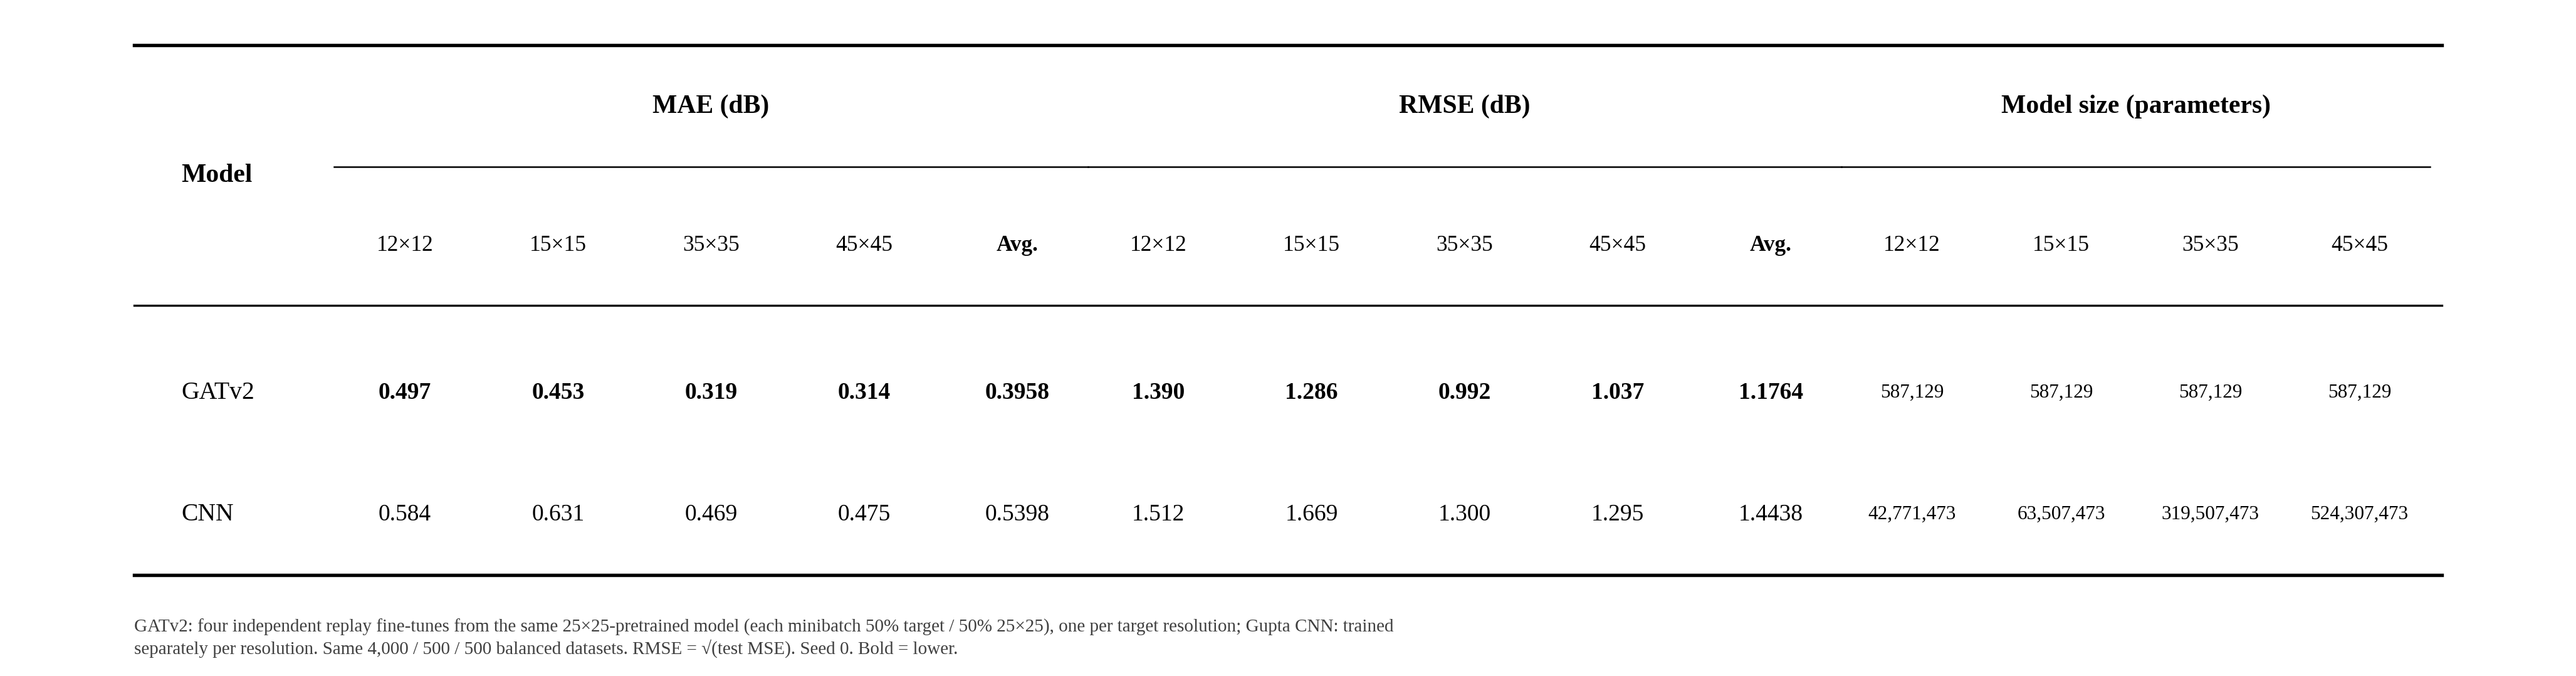

# Chunk 54 — Independent replay fine-tuning (50% target / 50% 25×25)

Four independent runs from best_model.pt (θ₀); each minibatch 32 target + 32 25×25. One test touch; 95% bootstrap intervals.

| run | grid | MSE (dB²) | RMSE (dB) | MAE (dB) | R² | MSE single-band | MSE non-functioning |
|---|---|---|---|---|---|---|---|
| ind_ft12_s0 | 12×12 | 1.933 [1.728, 2.132] | 1.390 | 0.497 [0.475, 0.519] | 0.642 | 3.098 [2.751, 3.466] | 0.768 [0.680, 0.866] |
| best_model | 12×12 | 5.059 [4.689, 5.474] | 2.249 | 0.850 [0.814, 0.888] | 0.064 | 6.653 [6.057, 7.307] | 3.465 [3.054, 3.938] |
| cnn12_bal_s0 | 12×12 | 2.287 [2.070, 2.507] | 1.512 | 0.584 [0.561, 0.606] | — | — | — |
| bal_ft45_s0 | 12×12 | 1.936 [1.728, 2.145] | 1.391 | 0.495 [0.472, 0.515] | — | — | — |
| ind_ft15_s0 | 15×15 | 1.653 [1.495, 1.834] | 1.286 | 0.453 [0.435, 0.474] | 0.735 | 2.604 [2.342, 2.866] | 0.702 [0.606, 0.810] |
| best_model | 15×15 | 4.351 [3.976, 4.730] | 2.086 | 0.785 [0.749, 0.818] | 0.302 | 6.469 [5.895, 

In [17]:
# ── Table image (letter Table I format) and report ──
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1
import matplotlib.pyplot as plt, textwrap
from matplotlib import font_manager
for f in glob.glob('/usr/share/fonts/truetype/liberation/*.ttf'):
    font_manager.fontManager.addfont(f)
FONT = next((f for f in ('Times New Roman', 'Liberation Serif', 'DejaVu Serif') if any(f == x.name for x in font_manager.fontManager.ttflist)), 'serif')
plt.rcParams.update({'font.family': 'serif', 'font.serif': [FONT], 'pdf.fonttype': 42})
CNN_P = {N: 6_163_473 - 257_000 + 256_000 * N * N + 1000 for N in TARGETS}
models = [('GATv2', {N: HEAD[N] for N in TARGETS}, {N: 587_129 for N in TARGETS})]
if get(f'cnn{TARGETS[0]}_bal_s0', TARGETS[0], 'mae_db') is not None:
    models.append(('CNN', {N: f'cnn{N}_bal_s0' for N in TARGETS}, CNN_P))
TAB = []
for name, ids, par in models:
    mae = [get(ids[N], N, 'mae_db').estimate for N in TARGETS]; rmse = [get(ids[N], N, 'rmse_db').estimate for N in TARGETS]
    TAB.append(dict(model=name, **{f'mae_{N}': v for N, v in zip(TARGETS, mae)}, mae_avg=np.mean(mae),
                    **{f'rmse_{N}': v for N, v in zip(TARGETS, rmse)}, rmse_avg=np.mean(rmse), **{f'params_{N}': par[N] for N in TARGETS}))
TAB = pd.DataFrame(TAB); TAB.to_csv(OUT('ch54_table_values.csv'), index=False)
fig = plt.figure(figsize=(13.5, 2.2 + 0.45 * len(TAB)), dpi=300); ax = fig.add_axes([0, 0, 1, 1]); ax.axis('off')
xs = np.r_[0.03, np.linspace(0.125, 0.385, 5), np.linspace(0.445, 0.705, 5), np.linspace(0.765, 0.955, 4)]
grp = [('MAE (dB)', xs[1:6]), ('RMSE (dB)', xs[6:11]), ('Model size (parameters)', xs[11:15])]
top = 0.92
for t, xx in grp:
    ax.text(xx.mean(), top, t, ha='center', va='center', fontsize=10, fontweight='bold'); ax.plot([xx[0] - .03, xx[-1] + .03], [top - .07] * 2, lw=.6, color='k')
sub = [f'{N}×{N}' for N in TARGETS]
for j, l in enumerate(sub + ['Avg.'] + sub + ['Avg.'] + sub):
    ax.text(xs[1 + j], top - .16, l, ha='center', va='center', fontsize=8.5, fontweight='bold' if l == 'Avg.' else 'normal')
ax.text(xs[0], top - .08, 'Model', ha='left', va='center', fontsize=10, fontweight='bold')
ax.plot([.01, .99], [top + .07] * 2, lw=1.3, color='k'); ax.plot([.01, .99], [top - .23] * 2, lw=.8, color='k')
y = top - .33
for r in TAB.itertuples():
    ax.text(xs[0], y, r.model, ha='left', va='center', fontsize=9.5)
    vals = [getattr(r, f'mae_{N}') for N in TARGETS] + [r.mae_avg] + [getattr(r, f'rmse_{N}') for N in TARGETS] + [r.rmse_avg]
    keys = [f'mae_{N}' for N in TARGETS] + ['mae_avg'] + [f'rmse_{N}' for N in TARGETS] + ['rmse_avg']
    for j, (v, k) in enumerate(zip(vals, keys)):
        best = TAB[k].min() == v and len(TAB) > 1
        ax.text(xs[1 + j], y, f'{v:.3f}' if 'avg' not in k else f'{v:.4f}', ha='center', va='center', fontsize=9, fontweight='bold' if best else 'normal')
    for j, N in enumerate(TARGETS):
        ax.text(xs[11 + j], y, f'{getattr(r, f"params_{N}"):,}', ha='center', va='center', fontsize=7.5)
    y -= .14
ax.plot([.01, .99], [y + .07] * 2, lw=1.3, color='k')
note = ('GATv2: four independent replay fine-tunes from the same 25×25-pretrained model (each minibatch 50% target / 50% 25×25), one per target '
        'resolution; Gupta CNN: trained separately per resolution. Same 4,000 / 500 / 500 balanced datasets. RMSE = √(test MSE). Seed 0. Bold = lower.')
ax.text(.01, y + .02, '\n'.join(textwrap.wrap(note, 170)), ha='left', va='top', fontsize=7, color='0.25')
for ext in ('png', 'pdf'):
    fig.savefig(OUT(f'ch54_table_gatv2_vs_cnn.{ext}'), dpi=600 if ext == 'png' else None, bbox_inches='tight', pad_inches=.05, facecolor='white')
plt.show(); plt.close(fig)

def fmt(mid, N, k, subset='all'):
    r = get(mid, N, k, subset)
    if r is None: return '—'
    return f'{r.estimate:.3f}' if np.isnan(r.lo) else f'{r.estimate:.3f} [{r.lo:.3f}, {r.hi:.3f}]'
L = ['# Chunk 54 — Independent replay fine-tuning (50% target / 50% 25×25)', '',
     'Four independent runs from best_model.pt (θ₀); each minibatch 32 target + 32 25×25. One test touch; 95% bootstrap intervals.', '',
     '| run | grid | MSE (dB²) | RMSE (dB) | MAE (dB) | R² | MSE single-band | MSE non-functioning |', '|---|---|---|---|---|---|---|---|']
for N in TARGETS:
    for mid in (HEAD[N], 'best_model', f'cnn{N}_bal_s0', 'bal_ft45_s0'):
        if get(mid, N, 'mse_db2') is None: continue
        L.append(f'| {mid} | {N}×{N} | {fmt(mid, N, "mse_db2")} | {fmt(mid, N, "rmse_db")} | {fmt(mid, N, "mae_db")} | {fmt(mid, N, "r2")} | '
                 f'{fmt(mid, N, "mse_db2", "single_band")} | {fmt(mid, N, "mse_db2", "non_functioning")} |')
L += ['', '## 25×25 retention (test set unchanged)', '| model | MSE | RMSE | MAE |', '|---|---|---|---|']
for mid in ['best_model'] + [HEAD[N] for N in TARGETS]:
    L.append(f'| {mid} | {fmt(mid, 25, "mse_db2")} | {fmt(mid, 25, "rmse_db")} | {fmt(mid, 25, "mae_db")} |')
L += ['', '## Paired comparisons (A − B, same test antennas)', PAIR.round(4).to_markdown(index=False), '',
      '## Pre-registered statements'] + [f'- **{k}:** {t}' for k, t in ANS.items()]
L += ['', '## Table values (letter Table I format)', TAB.round(4).to_markdown(index=False), '',
      '_Single-band and non-functioning antennas only (Chunk 51 balanced datasets); 25×25 test set natural._',
      '', '## Runs', RUNS_DF.drop(columns=['checkpoint_sha256'], errors='ignore').round(4).to_markdown(index=False)]
open(OUT('ch54_report.md'), 'w').write('\n'.join(L) + '\n'); print('\n'.join(L))

## 12. Guards
**What it checks:**
- one test touch
- all four seed-0 runs exist; every run started from the widened `best_model` (none from another run)
- every Chunk 54 checkpoint matches its recorded SHA-256
- no run was stopped by its epoch cap
- predicted curves were saved for every target-grid test antenna
- input files unchanged, and no earlier file modified
- every output named `ch54_*`

In [18]:
# ── Guards ──
fails = []
def guard(ok, msg):
    print(f"  [{'PASS' if ok else 'FAIL'}] {msg}")
    if not ok: fails.append(msg)
R2 = pd.read_csv(RUNS)
guard(TEST_TOUCHES == 1, 'TEST touched exactly once')
guard({rid(N, 0) for N in TARGETS} <= set(R2.run_id), 'all four seed-0 independent runs trained')
guard((R2.init == 'best_model.pt (+zero column)').all(), 'every run started from the widened best_model (independent runs)')
guard((R2.batch_composition == f'{HALF} target + {HALF} 25x25').all(), 'every run used 50% target / 50% 25x25 minibatches')
guard(all(sha(p) == h for p, h in zip(R2.checkpoint, R2.checkpoint_sha256)), 'every ch54 checkpoint matches its recorded SHA-256')
guard(not R2.budget_limited.any(), 'no run stopped by its epoch cap' if not R2.budget_limited.any() else
      f'BUDGET-LIMITED runs: {list(R2[R2.budget_limited].run_id)} (best epoch within 10 of the 60-epoch cap)')
P2 = pd.read_parquet(OUT('ch54_per_sample.parquet'))
tg = P2[P2.apply(lambda r: r.model_id in set(HEAD.values()) and r.model_id == HEAD.get(r.grid), axis=1)]
guard(len(tg) == 4 * 500 and tg.y_hat.map(lambda a: a is not None and len(a) == 201).all(), 'predicted curves saved for every target-grid test antenna')
guard(all(sha(p) == h for p, h in READ_SHA.items() if not Path(p).name.startswith('ch54_')), f'input files unchanged ({len(READ_SHA)})')
guard(all(os.path.getmtime(p) == t for p, t in PRIOR.items() if os.path.exists(p)), f'no earlier file modified ({len(PRIOR)})')
guard(all(Path(p).name.startswith('ch54_') for p in glob.glob(f'{ART}/ch54_*') + glob.glob(f'{CKPT}/ch54_*')), 'all outputs ch54_*')
assert not fails, fails
print('ALL GUARDS PASSED')

  [PASS] TEST touched exactly once
  [PASS] all four seed-0 independent runs trained
  [PASS] every run started from the widened best_model (independent runs)
  [PASS] every run used 50% target / 50% 25x25 minibatches
  [PASS] every ch54 checkpoint matches its recorded SHA-256
  [PASS] no run stopped by its epoch cap
  [PASS] predicted curves saved for every target-grid test antenna
  [PASS] input files unchanged (31)
  [PASS] no earlier file modified (314)
  [PASS] all outputs ch54_*
ALL GUARDS PASSED
